# Walmart Predict Weekly Sales

# Bloc 3 CDSD RNCP 35288 
# Schuyler Gilmer Goncalves

## Objectif

- Construire un modèle capable de prédire les ventes hebdomadaires `Weekly_Sales`
- Comprendre quelles variables sont liées aux ventes
- Comparer une régression linéaire simple avec une régression régularisée

## Etapes

- **Partie 1** : EDA et preprocessing.
- **Partie 2** : entraîner une **Linear Regression** comme baseline
- **Partie 3** : entraîner une régression régularisée Ridge
- **Partie 4** : `GridSearchCV` pour optimiser la force de régularisation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
from pathlib import Path
print(Path.cwd())

/Users/skygg/Documents/Github-Portfolio/wallmart_sales_analysis/notebooks


# Partie 1 : EDA et preprocessing


In [3]:
# Chargement des données

data = pd.read_csv("../data/Walmart_Store_sales.csv")

print("Dimensions :", data.shape)
display(data.head())
  

Dimensions : (150, 8)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,6.0,18-02-2011,1572117.54,NaN,59.61,3.045,214.777523,6.858
1,13.0,25-03-2011,1807545.43,0.0,42.38,3.435,128.616064,7.470
2,17.0,27-07-2012,NaN,0.0,NaN,NaN,130.719581,5.936
3,11.0,NaN,1244390.03,0.0,84.57,NaN,214.556497,7.346
4,6.0,28-05-2010,1644470.66,0.0,78.89,2.759,212.412888,7.092


## Qualité des données

- On vérifie :
  - les types ;
  - les valeurs manquantes ;
  - les statistiques descriptives.

In [4]:
print("Types :")
display(data.dtypes)

print("\nValeurs manquantes :")
display(data.isna().sum())

print("\nStatistiques descriptives :")
display(data.describe().round(2))

Types :


Store           float64
Date                str
Weekly_Sales    float64
Holiday_Flag    float64
Temperature     float64
Fuel_Price      float64
CPI             float64
Unemployment    float64
dtype: object


Valeurs manquantes :


Store            0
Date            18
Weekly_Sales    14
Holiday_Flag    12
Temperature     18
Fuel_Price      14
CPI             12
Unemployment    15
dtype: int64


Statistiques descriptives :


,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,150.00,136.00,138.00,132.00,136.00,138.00,135.00
mean,9.87,1249535.83,0.08,61.40,3.32,179.90,7.60
std,6.23,647463.04,0.27,18.38,0.48,40.27,1.58
min,1.00,268929.03,0.00,18.79,2.51,126.11,5.14
25%,4.00,605075.72,0.00,45.59,2.85,131.97,6.60
50%,9.00,1261423.86,0.00,62.98,3.45,197.91,7.47
75%,15.75,1806386.20,0.00,76.34,3.71,214.93,8.15
max,20.00,2771397.17,1.00,91.65,4.19,226.97,14.31



- Le dataset contient 150 observations.
- Plusieurs colonnes contiennent des valeurs manquantes.
- La cible `Weekly_Sales` contient des valeurs manquantes.
- Comme demandé dans l'énoncé :
  - on supprime les lignes où la cible est manquante 
  - on n'impute jamais la variable cible

In [5]:
# Suppression des cibles manquants
data = data.dropna(subset=["Weekly_Sales"]).copy()

print("Dimensions après suppression :", data.shape)


Dimensions après suppression : (136, 8)


## Transformation de la date

- La colonne `Date` ne peut pas être utilisée directement.
- On crée :
  - `Year`
  - `Month`
  - `Day`
  - `DayOfWeek`
- Puis on supprime `Date`.

In [6]:
data["Date"] = pd.to_datetime(
    data["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

data["Year"] = data["Date"].dt.year
data["Month"] = data["Date"].dt.month
data["Day"] = data["Date"].dt.day
data["DayOfWeek"] = data["Date"].dt.dayofweek

data = data.drop(columns=["Date"])

display(data.head())

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Day,DayOfWeek
0,6.0,1572117.54,NaN,59.61,3.045,214.777523,6.858,2011.0,2.0,18.0,4.0
1,13.0,1807545.43,0.0,42.38,3.435,128.616064,7.470,2011.0,3.0,25.0,4.0
3,11.0,1244390.03,0.0,84.57,NaN,214.556497,7.346,NaN,NaN,NaN,NaN
4,6.0,1644470.66,0.0,78.89,2.759,212.412888,7.092,2010.0,5.0,28.0,4.0
5,4.0,1857533.70,0.0,NaN,2.756,126.160226,7.896,2010.0,5.0,28.0,4.0



- Les dates connues correspondent toutes au vendredi (`DayOfWeek = 4`).
- `DayOfWeek` est donc constant sur les dates disponibles.
- Son coefficient devrait être nul ou quasi nul.
- On le conserve car il fait partie des variables demandées.

## Suppression des outliers

- L'énoncé définit les outliers avec la règle moyenne ± 3 écarts-types 
- Cette règle est appliquée à :
  - `Temperature`
  - `Fuel_Price`
  - `CPI`
  - `Unemployment`
- Les valeurs manquantes sont conservées pour être imputées ensuite.

In [7]:
outlier_columns = [
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment"
]

before_outliers = len(data)

for column in outlier_columns:
    mean = data[column].mean()
    std = data[column].std()

    lower = mean - 3 * std
    upper = mean + 3 * std

    data = data[
        data[column].isna()
        | data[column].between(lower, upper)
    ]

print("Lignes avant :", before_outliers)
print("Lignes après :", len(data))
print("Outliers supprimés :", before_outliers - len(data))

Lignes avant : 136
Lignes après : 131
Outliers supprimés : 5


### nettoyage

- Après suppression des cibles manquantes et des outliers, il reste 131 observations.
- Le dataset est petit.
- Des modèles linéaires simples sont donc adaptés

## Nettoyage des libellés catégoriels

- `Store` et `Holiday_Flag` sont des catégories.
- On transforme leurs valeurs en libellés simples

In [8]:
data["Store"] = data["Store"].apply(
    lambda x: str(int(x)) if pd.notna(x) else np.nan
)

data["Holiday_Flag"] = data["Holiday_Flag"].apply(
    lambda x: str(int(x)) if pd.notna(x) else np.nan
)

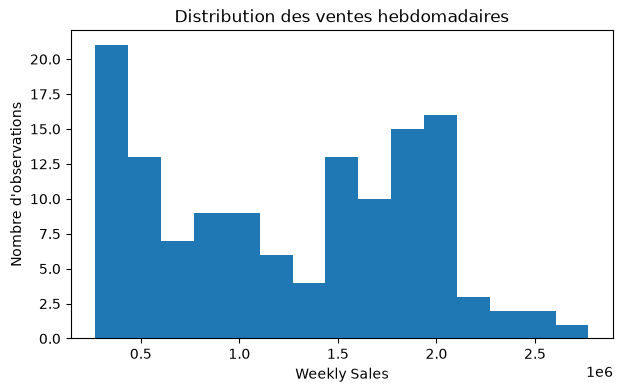

In [9]:
# Distribution des ventes

plt.figure(figsize=(7, 4))
plt.hist(data["Weekly_Sales"], bins=15)
plt.title("Distribution des ventes hebdomadaires")
plt.xlabel("Weekly Sales")
plt.ylabel("Nombre d'observations")
plt.show()

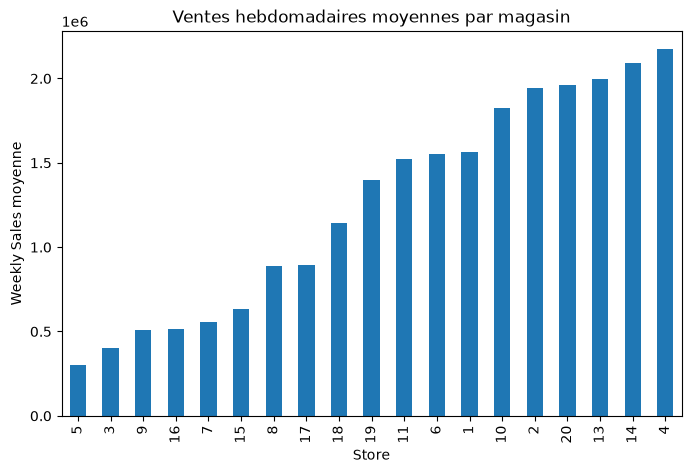

,Weekly_Sales_mean
Store,
5,302500.0
3,403055.0
9,506887.0
16,515318.0
7,559130.0
15,633580.0
8,888754.0
17,891606.0
18,1140437.0


In [10]:
# ventes moyenne par magasin

sales_by_store = (
    data.groupby("Store")["Weekly_Sales"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(8, 5))
sales_by_store.plot(kind="bar")
plt.title("Ventes hebdomadaires moyennes par magasin")
plt.xlabel("Store")
plt.ylabel("Weekly Sales moyenne")
plt.show()

display(sales_by_store.round(0).to_frame("Weekly_Sales_mean"))


- Les différences entre magasins sont très importantes.
- Les magasins `4`, `14`, `13`, `20` et `2` font partie des plus performants.
- Les magasins `5`, `3` et `9` ont des ventes moyennes plus faibles.
- `Store` devrait être une variable importante du modèle.

,mean,count
Holiday_Flag,,
0,1246016.0,112
1,1386763.0,8


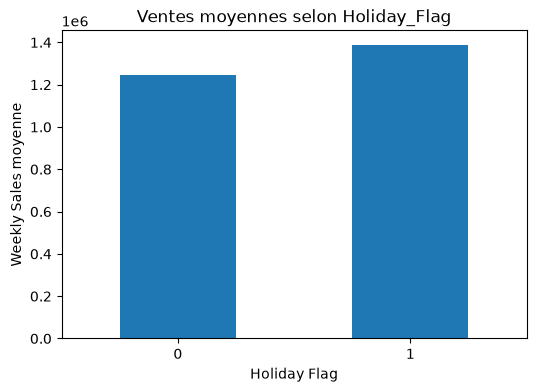

In [11]:
# Ventes et jours fériés 

holiday_sales = (
    data.groupby("Holiday_Flag")["Weekly_Sales"]
    .agg(["mean", "count"])
)

display(holiday_sales.round(0))

holiday_sales["mean"].plot(kind="bar", figsize=(6, 4))
plt.title("Ventes moyennes selon Holiday_Flag")
plt.xlabel("Holiday Flag")
plt.ylabel("Weekly Sales moyenne")
plt.xticks(rotation=0)
plt.show()


- En moyenne brute, les semaines `Holiday_Flag = 1` ont des ventes plus élevées.
- Mais ces semaines sont peu nombreuses.
- Cette comparaison ne contrôle pas les différences entre magasins ni les autres variables.
- Il faudra comparer cet insight aux coefficients du modèle multivarié.

In [12]:
# Corrélation numérique
numeric_for_corr = [
    "Weekly_Sales",
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment",
    "Year",
    "Month",
    "Day",
    "DayOfWeek"
]

correlations = (
    data[numeric_for_corr]
    .corr(numeric_only=True)["Weekly_Sales"]
    .sort_values(ascending=False)
)

display(correlations.round(3).to_frame("correlation_with_sales"))

,correlation_with_sales
Weekly_Sales,1.000
Unemployment,0.190
Fuel_Price,-0.008
Month,-0.013
Day,-0.036
Year,-0.040
Temperature,-0.156
CPI,-0.315
DayOfWeek,NaN



- `CPI` présente une corrélation brute négative avec les ventes.
- `Temperature` présente aussi une relation brute légèrement négative.
- Aucune variable économique seule n'explique parfaitement les ventes.
- Une corrélation brute peut changer lorsque le modèle contrôle simultanément le magasin et les autres variables.

## Préparation des données

### Variables catégorielles

- `Store`
- `Holiday_Flag`

### Variables numériques

- `Temperature`
- `Fuel_Price`
- `CPI`
- `Unemployment`
- `Year`
- `Month`
- `Day`
- `DayOfWeek`

### Preprocessing

- Numériques manquants : médiane
- Catégories manquantes : modalité la plus fréquente
- Numériques : `StandardScaler`
- Catégories : `OneHotEncoder`

In [13]:
target = "Weekly_Sales"

numeric_features = [
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment",
    "Year",
    "Month",
    "Day",
    "DayOfWeek"
]

categorical_features = [
    "Store",
    "Holiday_Flag"
]

features = categorical_features + numeric_features

X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=0
)

print("Train :", X_train.shape)
print("Test  :", X_test.shape)

Train : (104, 10)
Test  : (27, 10)


In [14]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Partie 2 : Baseline : Linear Regression

## Entraînement

In [15]:
linear_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Store','Holiday_Flag','Temperature',...,'Month','Day','DayOfWeek']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis

## Évaluation

- `R²` : part de variance expliquée.
- `MAE` : erreur absolue moyenne.
- `RMSE` : pénalise davantage les grosses erreurs.

In [16]:
def evaluate_model(model, name):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    return {
        "Model": name,
        "R2 train": r2_score(y_train, train_pred),
        "R2 test": r2_score(y_test, test_pred),
        "MAE test": mean_absolute_error(y_test, test_pred),
        "RMSE test": np.sqrt(mean_squared_error(y_test, test_pred))
    }

linear_results = evaluate_model(
    linear_model,
    "Linear Regression"
)

display(pd.DataFrame([linear_results]).round(3))

,Model,R2 train,R2 test,MAE test,RMSE test
0,Linear Regression,0.974,0.936,125063.469,155379.862


In [17]:
mean_weekly_sales = data["Weekly_Sales"].mean()
mae_linear = linear_results["MAE test"]
mae_percent = mae_linear / mean_weekly_sales * 100

print(f"Vente hebdomadaire moyenne : ${mean_weekly_sales:,.0f}")
print(f"MAE : ${mae_linear:,.0f}")
print(f"MAE / vente moyenne : {mae_percent:.1f}%")

Vente hebdomadaire moyenne : $1,257,990
MAE : $125,063
MAE / vente moyenne : 9.9%


###  baseline

- Le `R²` test est supérieur à 0,90.
- Le modèle explique donc une grande partie de la variance des ventes.
- Le MAE représente environ 10 % d'une vente hebdomadaire moyenne :
  - cela donne un ordre de grandeur métier
- Le `R²` train est supérieur au `R²` test :
  - un léger overfitting est possible.

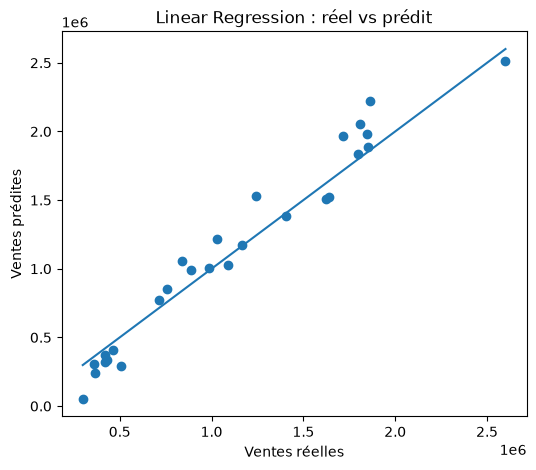

In [18]:
# Réel vs Prédit

linear_test_pred = linear_model.predict(X_test)

plt.figure(figsize=(6, 5))
plt.scatter(y_test, linear_test_pred)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)
plt.title("Linear Regression : réel vs prédit")
plt.xlabel("Ventes réelles")
plt.ylabel("Ventes prédites")
plt.show()

## Coefficients du modèle

- Les variables numériques sont standardisées :
  - leur coefficient correspond à une variation d'environ 1 écart-type
- Les variables catégorielles sont comparées à une catégorie de référence
- On regarde :
  - les plus gros coefficients 
  - puis spécifiquement les variables économiques

In [19]:
feature_names = (
    linear_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

coefficients = linear_model.named_steps["model"].coef_

coef_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coef_table["abs_coefficient"] = coef_table["coefficient"].abs()

display(
    coef_table
    .sort_values("abs_coefficient", ascending=False)
    .head(15)[["feature", "coefficient"]]
    .round(0)
)

,feature,coefficient
21,cat__Store_5,-1404353.0
25,cat__Store_9,-1275038.0
19,cat__Store_3,-1259269.0
13,cat__Store_16,-1101418.0
23,cat__Store_7,-881708.0
24,cat__Store_8,-753709.0
8,cat__Store_10,730671.0
11,cat__Store_14,726943.0
20,cat__Store_4,661399.0
14,cat__Store_17,-627062.0


## Coefficients économiques et temporels

- Cette table permet de ne pas masquer les variables économiques derrière les coefficients des magasins.

In [20]:
economic_features = [
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment",
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "Holiday_Flag"
]

economic_coefficients = coef_table[
    coef_table["feature"].str.contains(
        "|".join(economic_features),
        regex=True
    )
][["feature", "coefficient"]].copy()

display(
    economic_coefficients
    .sort_values("coefficient", ascending=False)
    .round(0)
)

,feature,coefficient
2,num__CPI,100864.0
5,num__Month,63293.0
7,num__DayOfWeek,0.0
4,num__Year,-19332.0
6,num__Day,-33576.0
0,num__Temperature,-37954.0
1,num__Fuel_Price,-40815.0
26,cat__Holiday_Flag_1,-47380.0
3,num__Unemployment,-97632.0



- `CPI` a une corrélation brute négative avec les ventes mais un coefficient positif dans le modèle.
- Cela signifie qu'une fois le magasin et les autres variables contrôlés, la relation estimée change de signe.

- `Holiday_Flag = 1` présente également :
  - une moyenne brute plus élevée dans l'EDA 
  - mais un coefficient négatif dans le modèle multivarié

- Il n'y a pas forcément contradiction :
  - l'EDA compare des groupes bruts 
  - le modèle estime l'association d'une variable à autres variables constantes

- `DayOfWeek` a un coefficient quasi nul, ce qui est cohérent avec son absence de variation.
- Les coefficients sont prédictifs et ne prouvent pas une causalité.

# Partie 3 : Régression régularisée : Ridge

##  Ridge avec `alpha = 1`

- Ridge pénalise les coefficients trop élevés.
- L'objectif est de réduire l'overfitting.

In [21]:
ridge_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

ridge_results = evaluate_model(
    ridge_model,
    "Ridge alpha=1"
)

display(
    pd.DataFrame([
        linear_results,
        ridge_results
    ]).round(3)
)

,Model,R2 train,R2 test,MAE test,RMSE test
0,Linear Regression,0.974,0.936,125063.469,155379.862
1,Ridge alpha=1,0.934,0.927,126396.962,166605.066


### Insight Ridge

- Avec `alpha = 1`, la régularisation réduit la performance
- Cela suggère que cette pénalisation est trop forte
- choisir `alpha` avec validation croisée.

# Optimisation de Ridge avec GridSearchCV

## Recherche du meilleur alpha

- GridSearchCV teste plusieurs valeurs d'alpha.
- La sélection est faite uniquement par validation croisée sur le train.


In [22]:
alphas = [
    0.001,
    0.01,
    0.1,
    1,
    10,
    100
]

ridge_grid_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", Ridge())
])

grid_search = GridSearchCV(
    estimator=ridge_grid_model,
    param_grid={"model__alpha": alphas},
    cv=5,
    scoring="neg_mean_squared_error"
)

grid_search.fit(X_train, y_train)

print(
    "Meilleur alpha selon la validation croisée :",
    grid_search.best_params_["model__alpha"]
)

Meilleur alpha selon la validation croisée : 0.001


## Diagnostic : R² selon alpha

- On affiche les scores train et test pour comprendre l'effet de la régularisation
- Ce graphique n'est pas utilisé pour choisir `alpha`.
- Le choix final reste celui de `GridSearchCV`.

In [23]:
alpha_results = []

for alpha in alphas:
    model_alpha = Pipeline([
        ("preprocessing", preprocessor),
        ("model", Ridge(alpha=alpha))
    ])

    model_alpha.fit(X_train, y_train)

    alpha_results.append({
        "alpha": alpha,
        "R2 train": r2_score(
            y_train,
            model_alpha.predict(X_train)
        ),
        "R2 test": r2_score(
            y_test,
            model_alpha.predict(X_test)
        )
    })

alpha_results = pd.DataFrame(alpha_results)

display(alpha_results.round(3))

,alpha,R2 train,R2 test
0,0.001,0.974,0.937
1,0.010,0.974,0.938
2,0.100,0.973,0.947
3,1.000,0.934,0.927
4,10.000,0.592,0.544
5,100.000,0.175,0.083


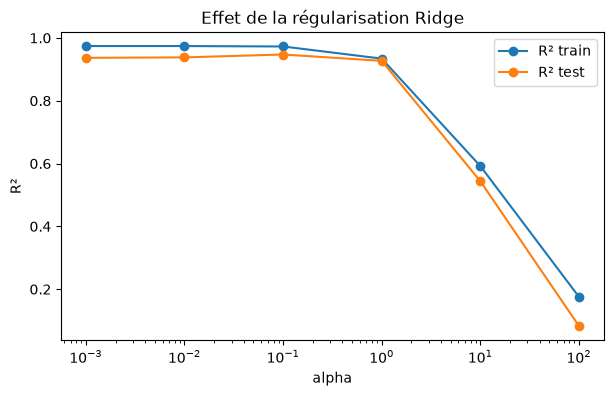

In [24]:
plt.figure(figsize=(7, 4))
plt.semilogx(
    alpha_results["alpha"],
    alpha_results["R2 train"],
    marker="o",
    label="R² train"
)
plt.semilogx(
    alpha_results["alpha"],
    alpha_results["R2 test"],
    marker="o",
    label="R² test"
)
plt.title("Effet de la régularisation Ridge")
plt.xlabel("alpha")
plt.ylabel("R²")
plt.legend()
plt.show()

- Les performances chutent fortement lorsque alpha devient trop grand.
- Une forte régularisation détruit donc une partie du signal utile
- alpha = 0.1 obtient un bon score sur ce test particulier.
- Mais on ne choisit pas 0.1 à partir du test :
  - cela reviendrait à optimiser sur les données d'évaluation ;
  - le choix final reste l'alpha sélectionné par validation croisée.

In [25]:
# Évaluation du Ridge sélectionné par GridSearchCV
best_ridge = grid_search.best_estimator_

best_ridge_results = evaluate_model(
    best_ridge,
    "Ridge optimisé"
)

comparison = pd.DataFrame([
    linear_results,
    ridge_results,
    best_ridge_results
])

display(comparison.round(3))

,Model,R2 train,R2 test,MAE test,RMSE test
0,Linear Regression,0.974,0.936,125063.469,155379.862
1,Ridge alpha=1,0.934,0.927,126396.962,166605.066
2,Ridge optimisé,0.974,0.937,124957.125,155185.298



- `GridSearchCV` choisit une régularisation très faible.
- La performance du Ridge optimisé est très proche de la Linear Regression
- Le dataset ne semble donc pas nécessiter une forte pénalisation
- La sélection par validation croisée est plus rigoureuse qu'un choix basé sur le meilleur score du test

# Conclusion

## Modélisation

- La **Linear Regression** est une baseline très performante.
- Le `R²` test est supérieur à **0,90**.
- Le MAE représente environ **10 %** de la vente hebdomadaire moyenne.
- Ridge avec `alpha = 1` régularise trop fortement.
- `GridSearchCV` sélectionne une régularisation très faible.
- La Linear Regression et le Ridge optimisé donnent donc des performances très proches.

## Insights métier

- Le magasin est le facteur prédictif le plus important
- Les ventes diffèrent fortement selon les magasins
- Les effets économiques doivent être lus dans le modèle multivarié :
  - `CPI` devient positif lorsque les autres variables sont contrôlées ;
  - `Unemployment`, `Fuel_Price` et `Temperature` ont des coefficients négatifs dans ce modèle.
- Les semaines fériées ont une moyenne brute plus élevée, mais le coefficient de `Holiday_Flag = 1` est négatif une fois les autres variables contrôlées.
- Cette différence entre EDA et modèle montre l'importance de distinguer :
  - comparaison brute ;
  - effet estimé à variables contrôlées.

## Limites

- Le dataset est petit : 131 observations après nettoyage.
- Certaines variables contiennent des valeurs manquantes.
- La règle des outliers est calculée avant le split :
  - comme indiqué dans l'énoncé
  - cela utilise une petite information globale sur la distribution.
- Les coefficients indiquent des associations et non des effets causaux